# Gaussian KAN laboratory

**Completed research and a workspace for your own experiments — 29 October 2026.**

Can a spline KAN transform independent uniform samples into an approximately Gaussian output law using unpaired target samples?

The measured answer is **yes, approximately**. The KAN learned a decreasing Gaussian quantile-like map. It beat the tested MLP, but its tails remain imperfect and a Gaussian parameter fit is much cheaper and more accurate when the Gaussian assumption is available.

Run the cells in order. Default execution checks the saved evidence and performs only a tiny recovery demonstration. Full study runs are loaded from saved checkpoints. New training is controlled by an explicit switch near the end.

Keep this notebook beside the study's Python modules and results. The portable bundle also includes checkpoints. A Git-only checkout can display the saved tables and figures, while weight-dependent cells need the checkpoint bundle or a deliberate rerun.

## The route through the experiment

1. Check the environment and configuration.
2. Generate independent latent and target sample sets.
3. Verify the sorted-sample loss, KAN forward pass, gradients, and updates.
4. Inspect checkpoints and demonstrate exact recovery.
5. Review training progress, baseline results, quantiles, and tails.
6. Compare seeds and spline capacity.
7. Choose an approach, train a new named run, resume it, and compare its output.

Distribution matching does not uniquely identify a physical stochastic mechanism. Increasing and decreasing quantile maps can generate the same Gaussian law.

In [1]:
from pathlib import Path
import os, sys, json, csv, math, hashlib, inspect, tempfile, subprocess
from dataclasses import asdict, replace
import importlib.metadata as package_metadata

here = Path.cwd().resolve()
candidates = [here, here / "experiments/gaussian_kan",
              here / "New-Denoising-Algorithm/experiments/gaussian_kan", here.parent]
ROOT = next((p for p in candidates if (p / "config/experiment.yaml").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the gaussian_kan study folder or its repository root.")
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
from scipy.special import ndtri
from IPython.display import display, Image, Code, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

from models import make_kan, make_mlp, parameter_count
from checkpoint import load_checkpoint
from train import uniform_open, wasserstein2_squared
from experiment_runner import ExperimentConfig, run_session, distribution_loss
from lab import load_artifact, compare_artifacts

METRICS = ROOT / "results/metrics"
FIGURES = ROOT / "results/figures"
HAS_WEIGHTS = (ROOT / "checkpoints/latest.pt").exists()
print("Study folder:", ROOT)
print("Saved model weights available:", HAS_WEIGHTS)

Study folder: C:\Users\saroy\.codex\.chatgpt-projects\g-p-6aaad21c30088191ba52fa7797bbe604\New-Denoising-Algorithm\experiments\gaussian_kan
Saved model weights available: True


## 1. Environment and fixed protocol

The original study used CPU because CUDA was unavailable. The KAN library is a genuine B-spline implementation, pinned to a specific source commit. Target parameters appear in data sampling and evaluation; the generator receives only latent values.

In [2]:
versions = {name: package_metadata.version(name) for name in
            ["torch", "numpy", "scipy", "matplotlib", "pandas", "efficient-kan", "nbformat", "ipykernel"]}
display(pd.Series(versions, name="Installed version").to_frame())
print("Python:", sys.version.split()[0], "| CUDA:", torch.cuda.is_available(),
      "| PyTorch CPU threads:", torch.get_num_threads())
study_config = yaml.safe_load((ROOT / "config/experiment.yaml").read_text())
display(pd.Series(study_config, name="Primary experiment").to_frame())

,Installed version
torch,2.14.1+cpu
numpy,2.5.2
scipy,1.18.1
matplotlib,3.11.2
pandas,3.0.6
efficient-kan,0.2.0
nbformat,5.11.1
ipykernel,7.4.0


Python: 3.12.14 | CUDA: False | PyTorch CPU threads: 4


,Primary experiment
experiment_id,kan_primary_seed_1729
model,kan
widths,"[1, 8, 8, 1]"
grid_intervals,32
spline_order,3
seed,1729
batch_size,2048
steps,1000
learning_rate,0.001
validation_size,8192


## 2. Independent, unpaired samples

The main study samples Z uniformly over the open unit interval and N from a zero-mean Gaussian with standard deviation 0.2. They are independent sample sets; there is no clean/noisy pair and no known target output for an individual latent value. Exact numerical endpoints are excluded.

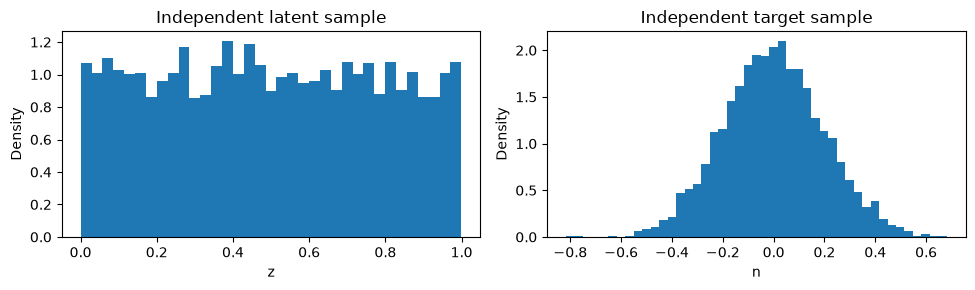

In [3]:
latent_rng = torch.Generator().manual_seed(101)
target_rng = torch.Generator().manual_seed(202)
z_demo = uniform_open((4096, 1), "cpu", latent_rng)
n_demo = torch.randn((4096, 1), generator=target_rng) * 0.2
assert ((z_demo > 0) & (z_demo < 1)).all()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(z_demo.numpy().ravel(), bins=35, density=True)
axes[0].set(title="Independent latent sample", xlabel="z", ylabel="Density")
axes[1].hist(n_demo.numpy().ravel(), bins=45, density=True)
axes[1].set(title="Independent target sample", xlabel="n", ylabel="Density")
plt.tight_layout(); plt.show()

## 3. Check the distribution loss

Sort generated and target samples independently, then average squared differences. This is empirical squared one-dimensional Wasserstein-2 distance for equal-sized samples. Permuting either set must leave it unchanged. Ordinary MSE between unrelated sample indices is not the objective.

In [4]:
generated_toy = torch.tensor([0.3, -0.2, 0.1, 0.05], requires_grad=True)
target_toy = torch.tensor([-0.4, 0.2, 0.1, 0.02])
loss_before = wasserstein2_squared(generated_toy, target_toy)
loss_permuted = wasserstein2_squared(generated_toy[[2, 0, 3, 1]], target_toy[[1, 3, 0, 2]])
assert torch.equal(loss_before, loss_permuted)
loss_before.backward()
assert torch.isfinite(generated_toy.grad).all() and generated_toy.grad.abs().sum() > 0
display(pd.DataFrame({
    "Quantity": ["Sorted squared W2", "After independent permutations", "Unpaired index-wise MSE"],
    "Value": [loss_before.item(), loss_permuted.item(),
              (generated_toy.detach() - target_toy).square().mean().item()]
}))
display(Code(inspect.getsource(distribution_loss), language="python"))

,Quantity,Value
0,Sorted squared W2,0.012725
1,After independent permutations,0.012725
2,Unpaired index-wise MSE,0.162725


def distribution_loss(output, target, kind="w2"):
    difference = output.flatten().sort().values - target.flatten().sort().values
    return difference.square().mean() if kind == "w2" else difference.abs().mean()

## 4. Inspect the spline KAN and one update

The primary network has widths [1, 8, 8, 1], 32 grid intervals, cubic B-splines, and 2,960 trainable parameters. Each edge has a learned univariate function. The library combines a base SiLU term with a B-spline expansion. This cell creates a temporary model; the saved study weights are not used for the update.

In [5]:
torch.manual_seed(314)
temporary_kan = make_kan([1, 8, 8, 1], 32, 3)
optimizer = torch.optim.Adam(temporary_kan.parameters(), lr=0.001)
before = [p.detach().clone() for p in temporary_kan.parameters()]
latent = uniform_open((128, 1), "cpu")
target = torch.randn((128, 1)) * 0.2
output = temporary_kan(latent)
loss = wasserstein2_squared(output, target)
optimizer.zero_grad(set_to_none=True); loss.backward()
assert output.shape == (128, 1)
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in temporary_kan.parameters())
optimizer.step()
change = max(float((a - p.detach()).abs().max()) for a, p in zip(before, temporary_kan.parameters()))
assert change > 0
display(pd.Series({"Parameters": parameter_count(temporary_kan), "Loss before update": loss.item(),
                   "Largest parameter change": change}, name="Forward/gradient/update check").to_frame())
display(Code(inspect.getsource(make_kan), language="python"))

,Forward/gradient/update check
Parameters,2960.000000
Loss before update,0.041025
Largest parameter change,0.001000


def make_kan(widths: list[int], grid_intervals: int, spline_order: int) -> KAN:
    if widths[0] != 1 or widths[-1] != 1:
        raise ValueError("generator must map one scalar to one scalar")
    return KAN(widths, grid_size=grid_intervals, spline_order=spline_order, grid_range=(-1.0, 1.0))

## 5. Checkpoints and faithful recovery

Each checkpoint includes weights, Adam state, step/configuration, Python/NumPy/PyTorch random states, validation measurements, and a reference to the best validation checkpoint. Atomic writes and periodic checkpoints provide recovery even when a shutdown hook cannot run.

The following inventory verifies selected checkpoint hashes from the recorded manifest. The next cell runs a tiny network continuously and in two sessions, then compares weights, optimizer tensors, and random state exactly.

In [6]:
manifest = json.loads((ROOT / "CHECKPOINT_MANIFEST.json").read_text())
inventory = pd.DataFrame(manifest["checkpoints"])
print("Recorded checkpoints:", len(inventory))
selected_paths = ["checkpoints/initial.pt", "checkpoints/step_000100.pt",
                  "checkpoints/best_step_000400.pt", "checkpoints/latest.pt"]
selected = inventory[inventory["path"].isin(selected_paths)].copy()
selected["available"] = selected["path"].map(lambda p: (ROOT / p).is_file())
if HAS_WEIGHTS:
    for row in selected.to_dict("records"):
        assert hashlib.sha256((ROOT / row["path"]).read_bytes()).hexdigest() == row["sha256"]
    checkpoint = load_checkpoint(ROOT / "checkpoints/latest.pt")
    assert checkpoint["step"] == 1000 and len(checkpoint["optimizer_state"]["state"]) > 0
    print("Final primary checkpoint random states:", sorted(checkpoint["rng_state"]))
display(selected[["path", "step", "bytes", "available", "sha256"]])

Recorded checkpoints: 215
Final primary checkpoint random states: ['numpy', 'python', 'torch_cpu', 'torch_cuda']


,path,step,bytes,available,sha256
66,checkpoints/best_step_000400.pt,400,64789,True,f622052f9f32e76798b10cd18957b119c0fcdff6ac68d3...
67,checkpoints/initial.pt,0,33594,True,aef1a5bbd1378299e429d0bd81cfc381c833d1e07a5eea...
68,checkpoints/latest.pt,1000,64265,True,a9289676c6029368542567ef6d9da7bdce9c38b9ef03c9...
96,checkpoints/step_000100.pt,100,64495,True,fd3390d573cb5cd6241c852141f58e8a570fe7c9f0e80a...


In [7]:
(ROOT / "explorations").mkdir(exist_ok=True)
demo_config = ExperimentConfig(run_id="continuous", widths=[1, 2, 1], grid_intervals=4,
                               seed=75, batch_size=32, validation_size=64,
                               steps=6, validate_every=3, checkpoint_every=3)
with tempfile.TemporaryDirectory(prefix="notebook_recovery_", dir=ROOT / "explorations") as folder:
    folder = Path(folder)
    run_session(demo_config, folder)
    split_config = replace(demo_config, run_id="split")
    first_session = run_session(split_config, folder, max_steps_per_session=3)
    second_session = run_session(split_config, folder, resume=True)
    a = load_checkpoint(folder / "continuous/checkpoints/latest.pt")
    b = load_checkpoint(folder / "split/checkpoints/latest.pt")
    assert all(torch.equal(value, b["model_state"][key]) for key, value in a["model_state"].items())
    assert torch.equal(a["rng_state"]["torch_cpu"], b["rng_state"]["torch_cpu"])
    for key, entry in a["optimizer_state"]["state"].items():
        assert all(torch.equal(value, b["optimizer_state"]["state"][key][item]) for item, value in entry.items())
print("Exact weights, optimizer state, and PyTorch RNG replay: PASSED")
print("First session:", first_session["status"], "| resumed session:", second_session["status"])

continuous: kan, 36 parameters, starting step 0


  step 3: val W2=0.195197


  step 6: val W2=0.194242


split: kan, 36 parameters, starting step 0


  step 3: val W2=0.195197


split: kan, 36 parameters, starting step 3


  step 6: val W2=0.194242


Exact weights, optimizer state, and PyTorch RNG replay: PASSED
First session: interrupted | resumed session: completed


## 6. Follow the primary training run

The saved primary trajectory started with a very narrow output distribution, improved through 1,000 steps, and selected step 400 by fixed-validation W2. Training and validation fluctuate because fresh unpaired mini-batches have finite-sample variation. Best and final checkpoints are both preserved.

,step,train_w2_squared,val_w2_squared,output_mean,output_std,grad_norm,elapsed_seconds
0,0,NaN,0.035745,-0.018812,0.010543,NaN,0.000000
1,20,0.022183,0.020002,-0.020568,0.065409,0.058846,1.950593
3,30,0.013527,0.012774,-0.019697,0.103937,0.045527,3.504952
7,100,0.000543,0.000591,-0.000108,0.197027,0.003967,11.272132
19,400,0.000136,0.000037,0.004155,0.198164,0.006717,44.004385
43,1000,0.000066,0.000146,-0.006476,0.197306,0.005409,108.574910


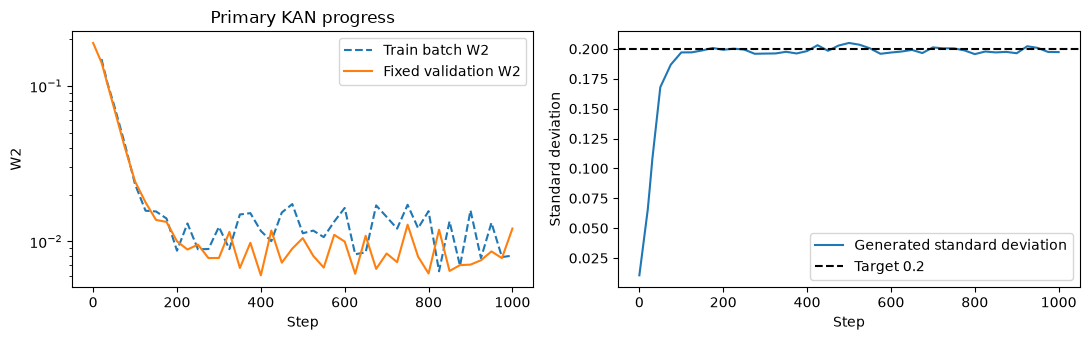

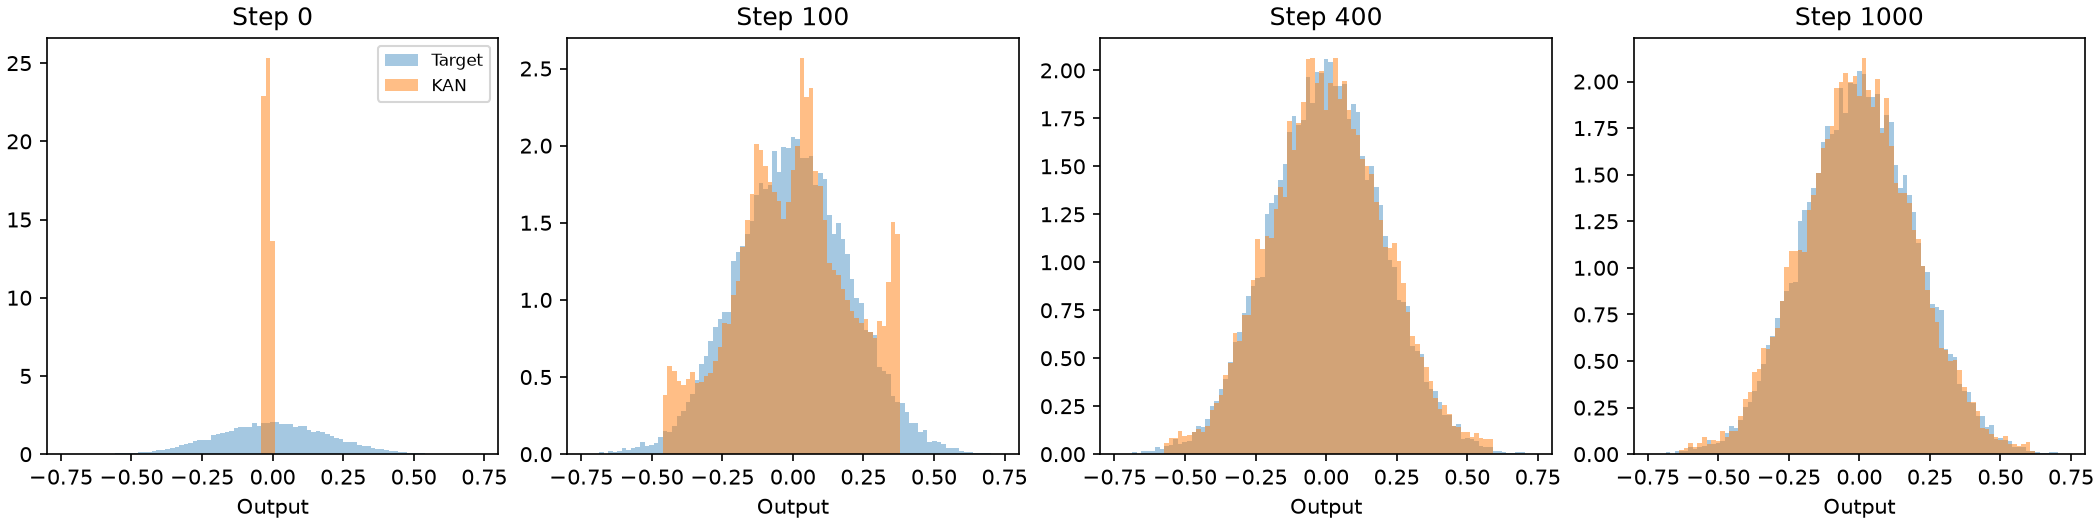

In [8]:
history = pd.read_csv(METRICS / "kan_primary_seed_1729.csv")
display(history[history["step"].isin([0, 20, 30, 100, 400, 1000])])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(history["step"], np.sqrt(history["train_w2_squared"]), "--", label="Train batch W2")
axes[0].plot(history["step"], np.sqrt(history["val_w2_squared"]), label="Fixed validation W2")
axes[0].set(yscale="log", xlabel="Step", ylabel="W2", title="Primary KAN progress")
axes[0].legend()
axes[1].plot(history["step"], history["output_std"], label="Generated standard deviation")
axes[1].axhline(0.2, color="black", linestyle="--", label="Target 0.2")
axes[1].set(xlabel="Step", ylabel="Standard deviation")
axes[1].legend()
plt.tight_layout(); plt.show()
display(Image(filename=str(FIGURES / "distribution_snapshots.png"), width=1100))

## 7. Compare the completed baselines

These are the **first independent test** results: 100,000 uniform inputs and an independent 100,000-sample target set, unused for checkpoint selection. The MLP has 2,913 parameters, approximately matching the KAN. The Gaussian parameter fit and oracle explicitly use Gaussian knowledge. The empirical affine fit uses sorted unpaired training samples without assuming a Gaussian family.

The validation-selected checkpoint and final checkpoint are reported separately. A test result does not change the preselected checkpoint.

,method,test_w2,mean_error,std_error,parameters,selected_step,training_loop_seconds,uses_gaussian_family
0,KAN best,0.007763,0.004309,-0.000669,2960,400,108.897600,False
1,KAN final,0.007481,-0.006308,-0.001445,2960,1000,108.897600,False
2,MLP best,0.042940,0.003218,-0.006499,2913,900,3.363105,False
3,Affine Adam best,0.047650,-0.000755,-0.024567,2,1000,2.899016,False
4,Affine empirical fit,0.043003,-0.000475,-0.004345,2,analytic,NaN,False
5,Gaussian parameter fit,0.001646,-0.000538,0.000049,2,analytic,NaN,True
6,True inverse-CDF oracle,0.001658,-0.000421,0.000025,0,analytic,NaN,True


Gaussian-versus-Gaussian W2 reference: 0.001555 ± 0.000336 (SD, 10 pairs)


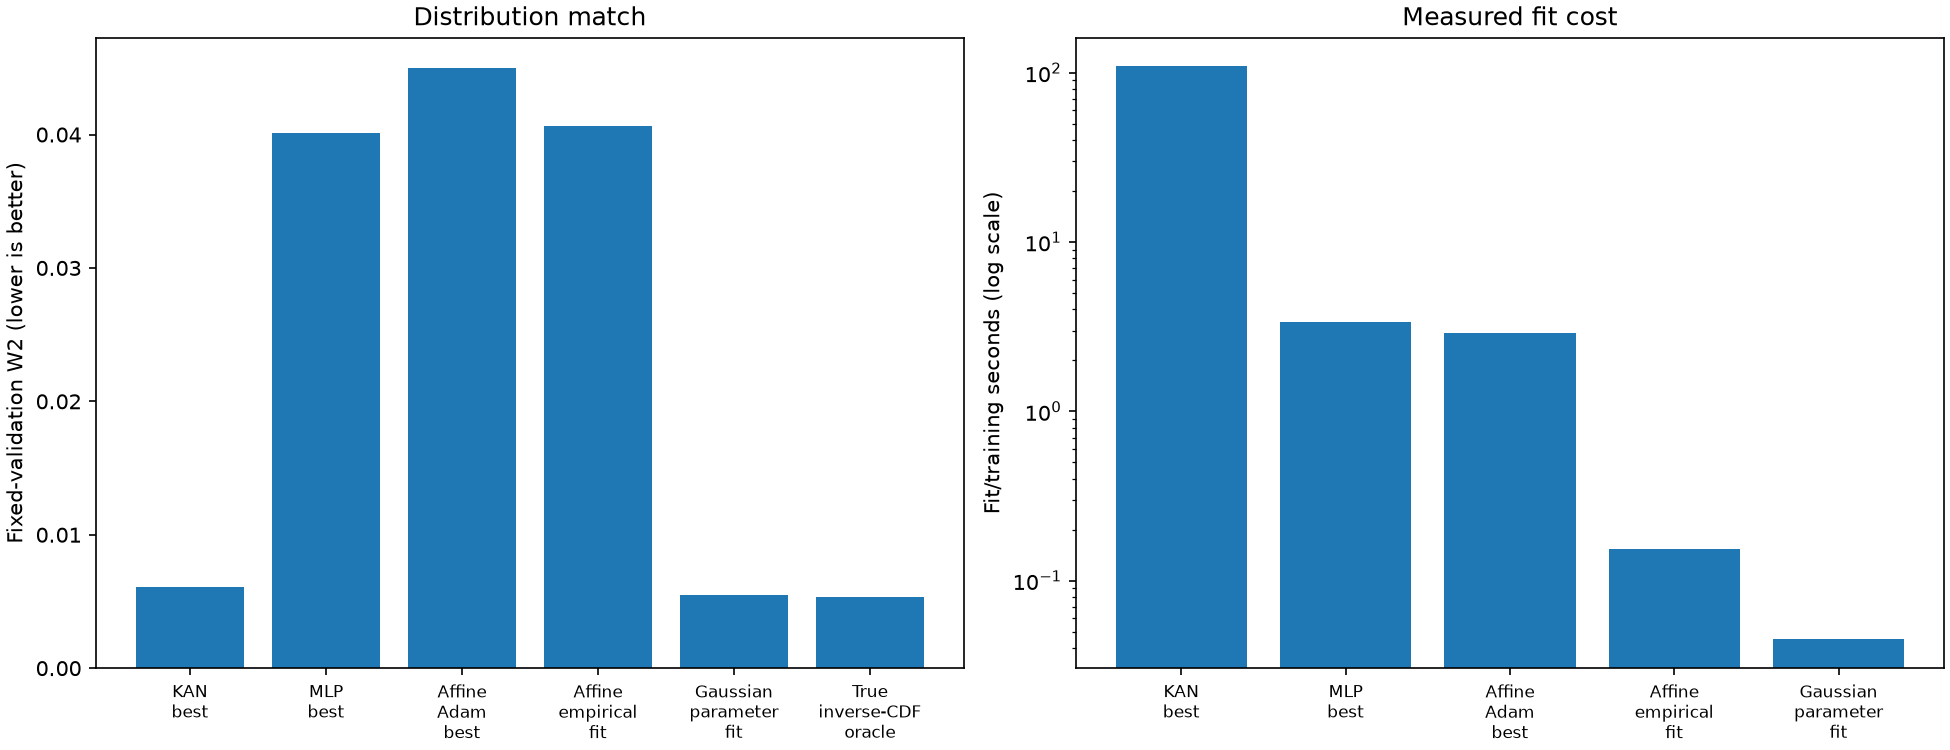

In [9]:
test_results = pd.read_csv(METRICS / "independent_test_metrics.csv")
display(test_results[["method", "test_w2", "mean_error", "std_error", "parameters",
                      "selected_step", "training_loop_seconds", "uses_gaussian_family"]].round(6))
floor = json.loads((METRICS / "sampling_floor.json").read_text())
print(f"Gaussian-versus-Gaussian W2 reference: {floor['mean_w2']:.6f} ± {floor['sd_w2']:.6f} (SD, 10 pairs)")
display(Image(filename=str(FIGURES / "baseline_comparison.png"), width=1000))

## 8. Inspect any saved generators yourself

Edit the method list, sample size, and seed below. This computes a fresh comparison without training or altering saved weights. The sample variation can change small differences between methods. Use the published tables for the recorded study results.

Available aliases: kan_best, kan_final, mlp_best, affine_best, affine_empirical, gaussian_fit, oracle. You can also use any completed robustness run ID or your own saved exploration run ID.

,artifact,W2,mean_error,std_error,parameters,Gaussian_assumption,status
0,kan_best,0.008030,0.004730,0.000296,2960,False,completed/reference
1,mlp_best,0.042237,0.002815,-0.006243,2913,False,completed/reference
2,gaussian_fit,0.002881,-0.000938,0.001151,2,True,completed/reference


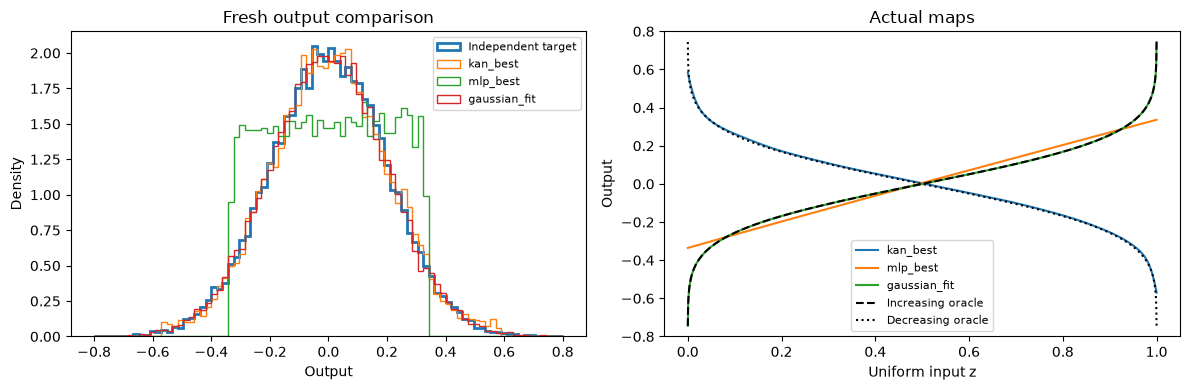

In [10]:
METHODS_TO_INSPECT = ["kan_best", "mlp_best", "gaussian_fit"]
INSPECTION_SIZE = 20000
INSPECTION_SEED = 7101

if HAS_WEIGHTS:
    comparison, latent_view, target_view, output_view = compare_artifacts(
        METHODS_TO_INSPECT, sample_size=INSPECTION_SIZE, seed=INSPECTION_SEED)
    display(pd.DataFrame(comparison).round(6))
    grid = np.linspace(1e-4, 1 - 1e-4, 1500, dtype=np.float32)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    edges = np.linspace(-0.8, 0.8, 85)
    axes[0].hist(target_view, bins=edges, density=True, histtype="step", lw=2, label="Independent target")
    for name in METHODS_TO_INSPECT:
        axes[0].hist(output_view[name], bins=edges, density=True, histtype="step", label=name)
        axes[1].plot(grid, load_artifact(name).predict(grid), label=name)
    axes[1].plot(grid, .2 * ndtri(grid), "k--", label="Increasing oracle")
    axes[1].plot(grid, -.2 * ndtri(grid), "k:", label="Decreasing oracle")
    axes[0].set(xlabel="Output", ylabel="Density", title="Fresh output comparison")
    axes[1].set(xlabel="Uniform input z", ylabel="Output", title="Actual maps", ylim=(-.8, .8))
    for ax in axes: ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("Load the checkpoint bundle to run live saved-model comparisons. Published evidence remains visible below.")

## 9. Quantiles, monotonicity, and tails

A similar histogram is insufficient. The selected KAN map was strictly decreasing on 10,000 interior points and had RMSE 0.00642 against the decreasing quantile reference. The inverse CDF is unbounded at z=0 and z=1, whereas these finite models flatten. Extreme-tail errors remain visible in quantiles and exceedance probabilities.

,orientation,interior_rmse_increasing,interior_rmse_decreasing,fraction_increasing_differences,fraction_decreasing_differences,interior_max_absolute_error_chosen
KAN best,decreasing,0.399053,0.006421,0.0,1.0,0.173829
KAN final,decreasing,0.398317,0.007855,0.0,1.0,0.135859
MLP best,increasing,0.04205,0.391047,1.0,0.0,0.408164
Affine Adam best,decreasing,0.373061,0.046687,0.0,1.0,0.441143


probability,0.001,0.010,0.990,0.999
method,,,,
Affine Adam best,0.313985,0.166615,-0.168846,-0.315950
Affine empirical fit,0.279813,0.133363,-0.133507,-0.280253
Gaussian parameter fit,0.001447,0.002544,0.000169,-0.003918
KAN best,0.060549,-0.000188,0.014607,-0.045296
KAN final,0.009652,-0.010319,-0.003775,-0.029684
MLP best,0.283059,0.136836,-0.135583,-0.282468
True inverse-CDF oracle,0.001637,0.002715,0.000231,-0.003874


,method,absolute_threshold,observed_fraction,theoretical_fraction
3,KAN best,0.6,0.00000,0.0027
7,KAN final,0.6,0.00193,0.0027
11,MLP best,0.6,0.00000,0.0027
15,Affine Adam best,0.6,0.00000,0.0027
19,Affine empirical fit,0.6,0.00000,0.0027
23,Gaussian parameter fit,0.6,0.00266,0.0027
27,True inverse-CDF oracle,0.6,0.00266,0.0027


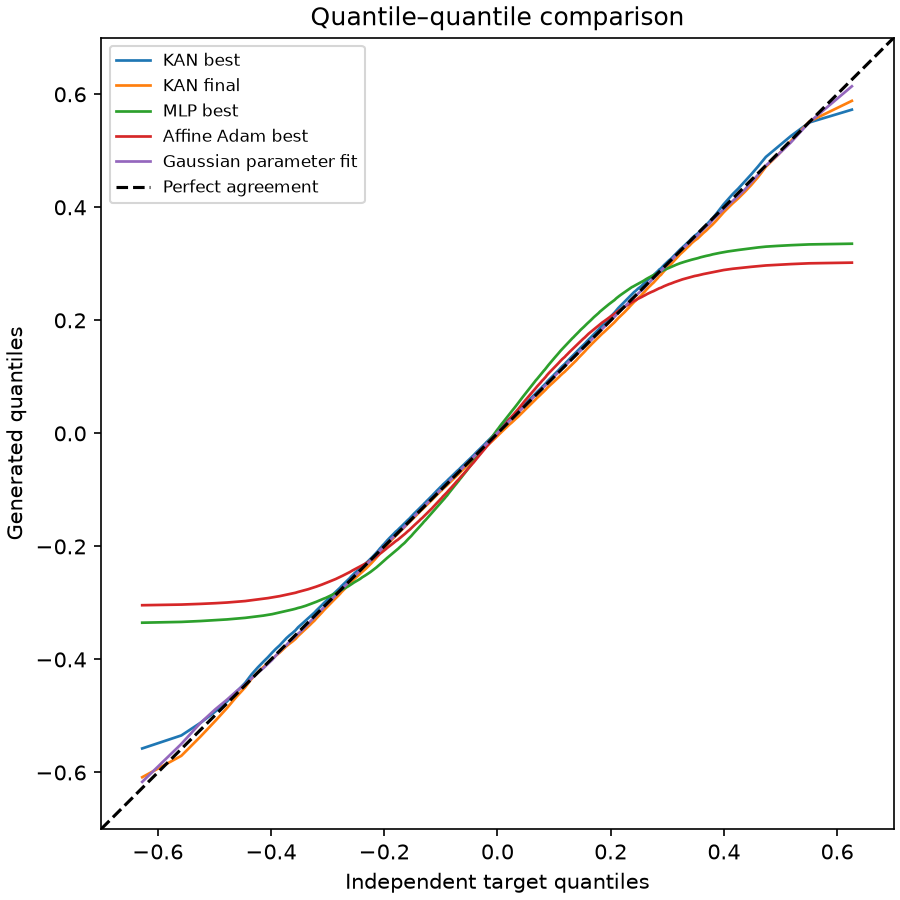

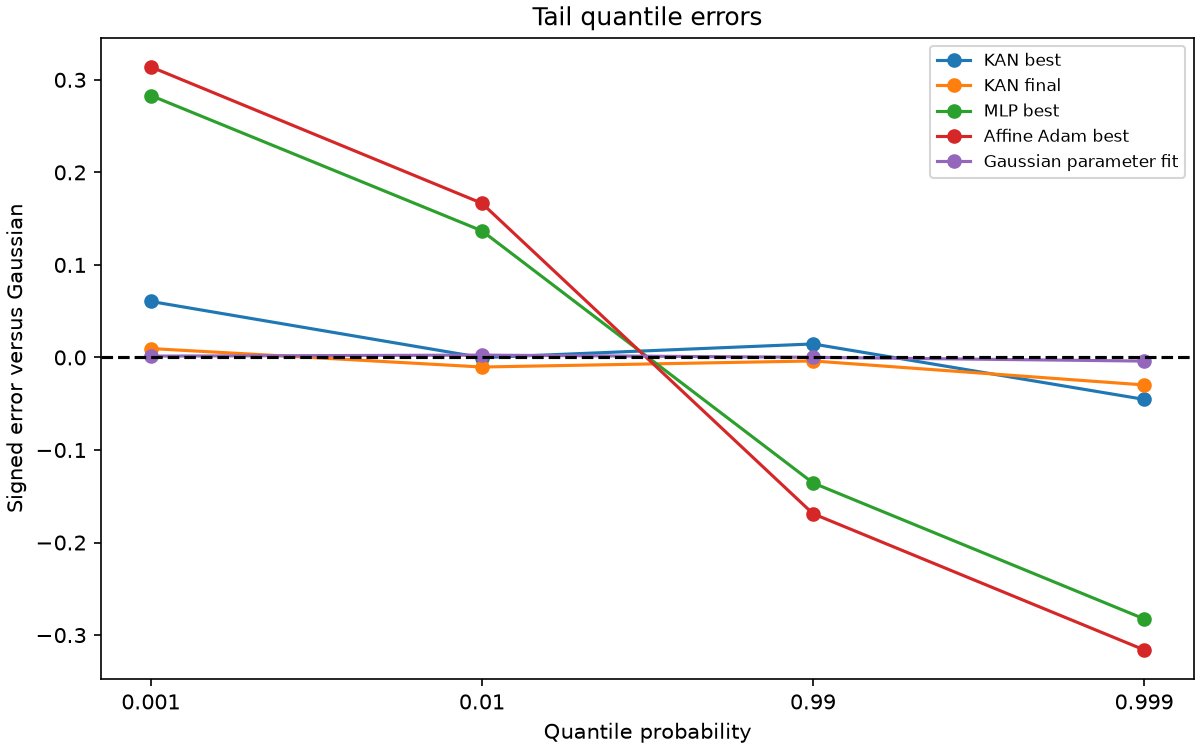

In [11]:
diagnostics = pd.DataFrame(json.loads((METRICS / "function_diagnostics.json").read_text())).T
display(diagnostics[["orientation", "interior_rmse_increasing", "interior_rmse_decreasing",
                     "fraction_increasing_differences", "fraction_decreasing_differences",
                     "interior_max_absolute_error_chosen"]])
quantiles = pd.read_csv(METRICS / "quantile_errors.csv")
display(quantiles[quantiles["probability"].isin([.001, .01, .99, .999])]
        .pivot(index="method", columns="probability", values="signed_error").round(6))
tails = pd.read_csv(METRICS / "tail_fractions.csv")
display(tails[tails["absolute_threshold"] == .6].round(6))
display(Image(filename=str(FIGURES / "independent_qq.png"), width=650))
display(Image(filename=str(FIGURES / "tail_quantile_errors.png"), width=850))

## 10. Stability and how much capacity was needed

Two additional primary seeds, a smaller [1,8,1] KAN, and a 64-grid primary KAN were run under the fixed training protocol. The table uses a fresh confirmation pair. Primary three-seed W2 averaged 0.00584 (SD 0.00051). The 592-parameter KAN was the smallest tested and retained similar central-distribution accuracy. It does not establish a minimum. Finer resolution improved some tail errors, but optimization variation was comparable to the overall accuracy gain.

Timing across different sessions is indicative: the first primary run used another runner/session. Compare same-session timings or repeat controlled benchmarks before attributing runtime differences to architecture.

,run_id,parameters,selected_step,confirmation_w2,final_confirmation_w2,interior_map_rmse,q001_error,q999_error,training_loop_seconds
0,kan_primary_seed_1729,2960,400,0.006242,0.008785,0.006421,0.060774,-0.047826,108.897600
1,kan_primary_seed_1730,2960,975,0.006020,0.006121,0.005997,0.047214,-0.033259,31.006735
2,kan_primary_seed_1731,2960,925,0.005266,0.005937,0.005924,0.038731,0.000439,31.936373
3,kan_small32_seed_1729,592,700,0.006627,0.005008,0.006595,0.064662,-0.064190,18.551916
4,kan_primary64_seed_1729,5520,450,0.005765,0.004878,0.005718,0.041296,-0.011702,54.416379


Three primary seeds: 0.005842506044018809 ± 0.0005116297915276851 (sample SD)


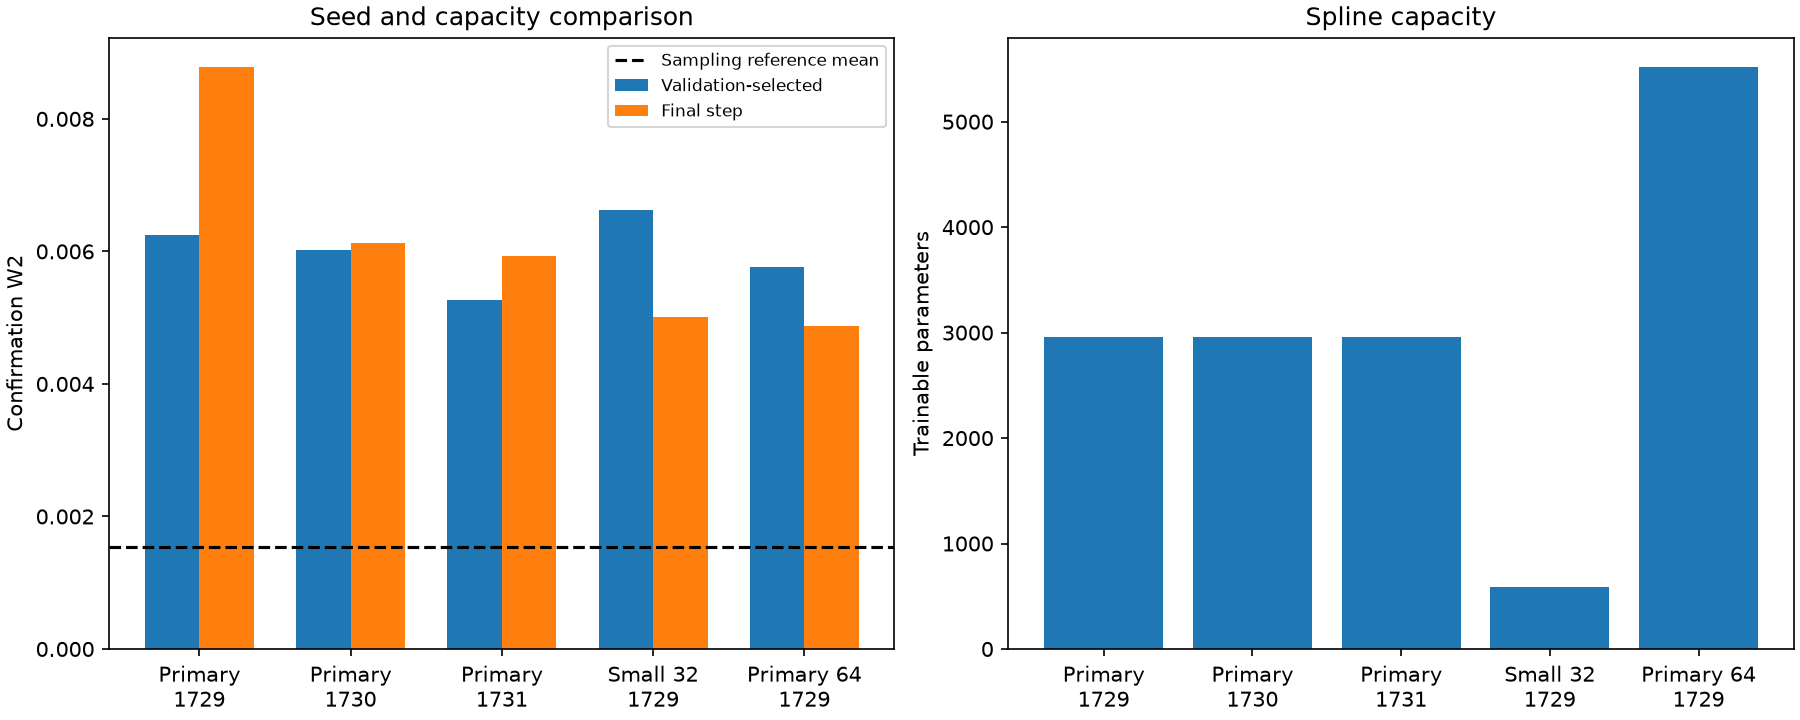

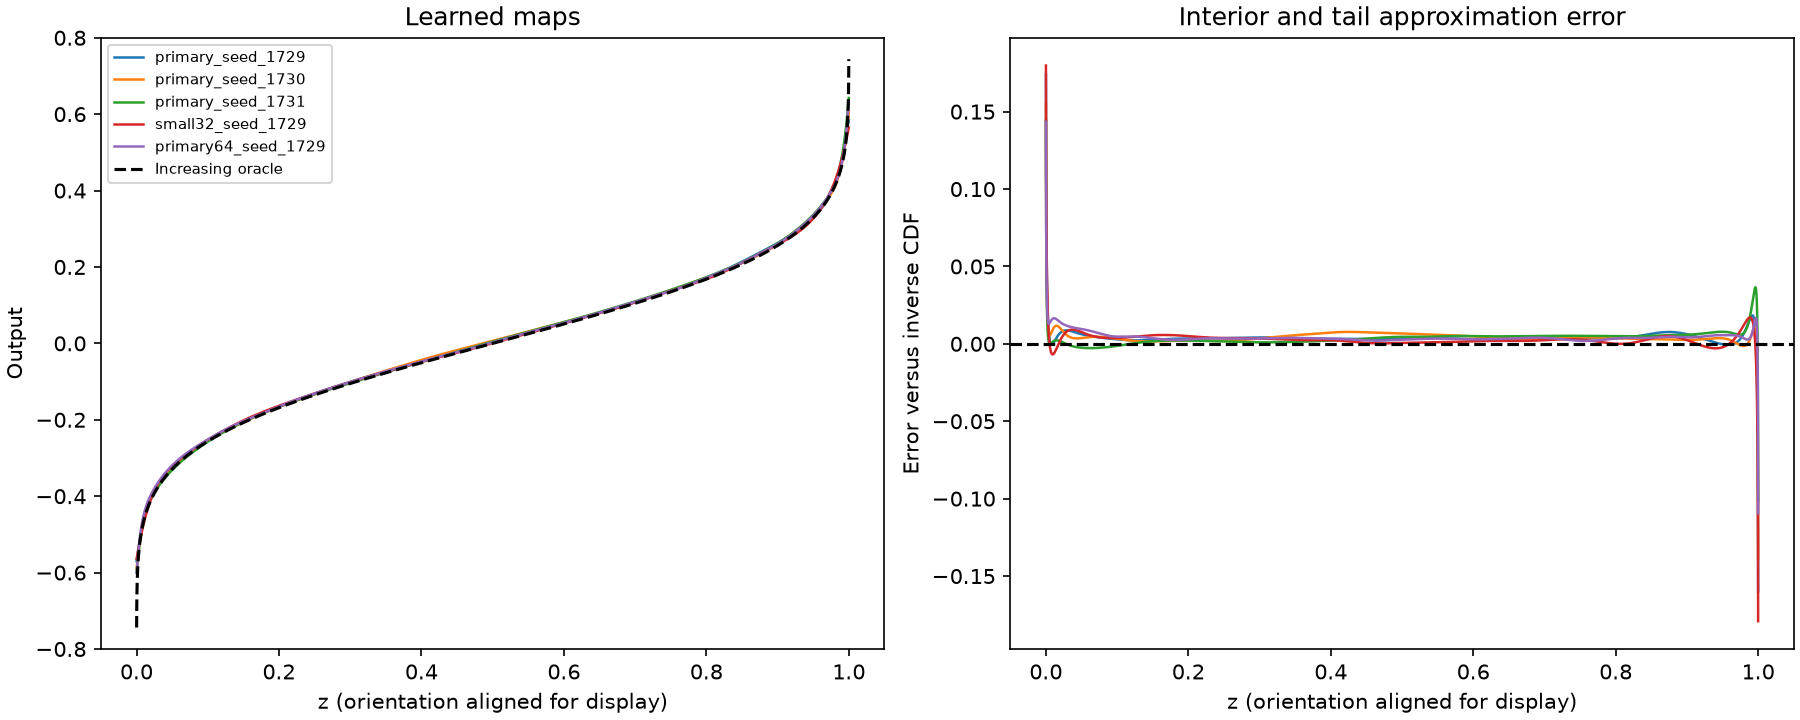

In [12]:
robustness = pd.read_csv(METRICS / "robustness_comparison.csv")
display(robustness[["run_id", "parameters", "selected_step", "confirmation_w2",
                    "final_confirmation_w2", "interior_map_rmse", "q001_error",
                    "q999_error", "training_loop_seconds"]].round(6))
robust_summary = json.loads((METRICS / "robustness_summary.json").read_text())
print("Three primary seeds:", robust_summary["primary_three_seed_mean_w2"],
      "±", robust_summary["primary_three_seed_sd_w2"], "(sample SD)")
display(Image(filename=str(FIGURES / "robustness_comparison.png"), width=1000))
display(Image(filename=str(FIGURES / "capacity_maps.png"), width=1000))

## 11. Try another approach

Choose a recipe and edit the configuration. Main-study results always use squared W2 and Adam. The W1 recipe is an optional different objective, and the MLP recipes allow an activation comparison. None of these optional recipes is reported as a completed research result unless you actually run it.

Use a unique run name for a new configuration. An existing run cannot be silently overwritten. To continue the same configuration, explicitly set RESUME_EXPERIMENT=True. Validation always measures squared W2, including when training with W1.

In [13]:
APPROACH_RECIPES = {
    "small_kan": {"model": "kan", "widths": [1, 8, 1], "grid_intervals": 32},
    "primary_kan": {"model": "kan", "widths": [1, 8, 8, 1], "grid_intervals": 32},
    "finer_kan": {"model": "kan", "widths": [1, 8, 8, 1], "grid_intervals": 64},
    "mlp_silu": {"model": "mlp", "widths": [1, 52, 52, 1], "activation": "silu"},
    "mlp_tanh": {"model": "mlp", "widths": [1, 52, 52, 1], "activation": "tanh"},
    "affine": {"model": "affine", "widths": [1, 1]},
    "small_kan_w1": {"model": "kan", "widths": [1, 8, 1], "grid_intervals": 32, "loss": "w1"},
}
APPROACH = "small_kan"             # change to any recipe above
RUN_NAME = "my_small_kan_001"      # use a NEW name for changed configurations
EXPERIMENT = ExperimentConfig(
    run_id=RUN_NAME, **APPROACH_RECIPES[APPROACH],
    seed=777, steps=1000, batch_size=2048, learning_rate=0.001,
)
EXPERIMENT.check()
display(pd.Series(asdict(EXPERIMENT), name="Your editable experiment").to_frame())

,Your editable experiment
run_id,my_small_kan_001
model,kan
widths,"[1, 8, 1]"
grid_intervals,32
spline_order,3
activation,silu
seed,777
batch_size,2048
steps,1000
learning_rate,0.001


In [14]:
RUN_NEW_EXPERIMENT = False
RESUME_EXPERIMENT = False
MAX_SESSION_SECONDS = 60
MAX_SESSION_STEPS = 200

if RUN_NEW_EXPERIMENT:
    result = run_session(
        EXPERIMENT, ROOT / "explorations",
        resume=RESUME_EXPERIMENT,
        max_runtime_seconds=MAX_SESSION_SECONDS,
        max_steps_per_session=MAX_SESSION_STEPS,
    )
    display(pd.Series(result, name="Session result").to_frame())
else:
    print("New training is disabled. Set RUN_NEW_EXPERIMENT=True to execute the configuration above.")
    print("To continue it later, keep the same configuration and set RESUME_EXPERIMENT=True.")

New training is disabled. Set RUN_NEW_EXPERIMENT=True to execute the configuration above.
To continue it later, keep the same configuration and set RESUME_EXPERIMENT=True.


After your run has a saved checkpoint, add its run name to the comparison below. Interrupted runs can be inspected too; their status is displayed. Use the same comparison sample size and seeds across candidates. Keep a further untouched test sample if you use these comparisons to select an approach.

Not run / weights unavailable: my_small_kan_001


,artifact,W2,mean_error,std_error,parameters,Gaussian_assumption,status
0,kan_best,0.006472,0.001203,0.000815,2960,False,completed/reference
1,kan_small32_seed_1729,0.007107,0.000050,-0.000093,592,False,completed


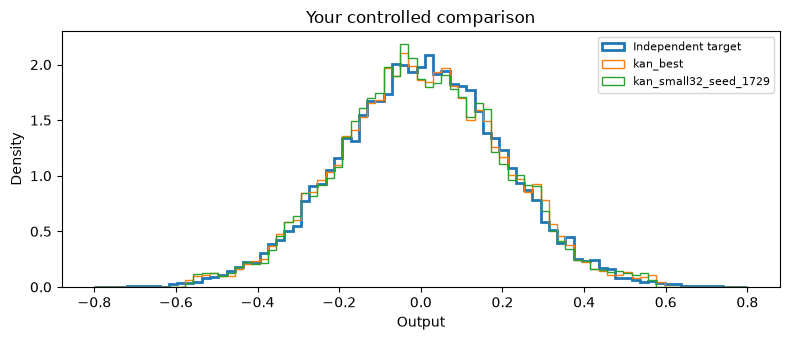

In [15]:
USER_COMPARISON = ["kan_best", "kan_small32_seed_1729", RUN_NAME]
available = []
for name in USER_COMPARISON:
    try:
        artifact = load_artifact(name)
        available.append(name)
    except FileNotFoundError:
        print("Not run / weights unavailable:", name)
if available:
    rows, z_user, target_user, generated_user = compare_artifacts(
        available, sample_size=20000, seed=8801)
    display(pd.DataFrame(rows).round(6))
    fig, ax = plt.subplots(figsize=(8, 3.5))
    edges = np.linspace(-.8, .8, 80)
    ax.hist(target_user, bins=edges, density=True, histtype="step", lw=2, label="Independent target")
    for name in available:
        ax.hist(generated_user[name], bins=edges, density=True, histtype="step", label=name)
    ax.set(xlabel="Output", ylabel="Density", title="Your controlled comparison")
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 12. Verify the saved study artifacts

This runs the recorded checkpoint, independent-evaluation, and robustness checks. It does not restart a completed 1,000-step experiment. The pilot recovery check deliberately replays ten steps in memory.

In [16]:
RUN_ARTIFACT_CHECKS = True
if RUN_ARTIFACT_CHECKS and HAS_WEIGHTS:
    commands = [
        [sys.executable, str(ROOT / "scripts/build_checkpoint_manifest.py"), "--verify"],
        [sys.executable, str(ROOT / "tests/test_resume.py")],
        [sys.executable, str(ROOT / "tests/test_baseline_artifacts.py")],
        [sys.executable, str(ROOT / "tests/test_evaluation_artifacts.py")],
        [sys.executable, str(ROOT / "tests/test_robustness_artifacts.py")],
    ]
    for command in commands:
        completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
        print(completed.stdout.strip())
        if completed.returncode:
            print(completed.stderr)
            raise RuntimeError(f"Artifact check failed: {command[-1]}")
else:
    print("Artifact replay checks skipped; use the portable checkpoint bundle to enable them.")

Verified 215 checkpoint hashes


Exact 10-step model and PyTorch RNG replay passed


Baseline checkpoints and shared validation metrics verified


Independent metrics, quantiles, sampling reference, and six figures verified


All four robustness runs, 40 periodic checkpoints, and confirmation summary verified


## Interpretation and next experiment

- The KAN learned an approximate Gaussian output law from unpaired samples and a monotone decreasing quantile-like transformation.
- Central approximation is good, but extreme tails and finite-batch optimization remain measurable limitations.
- A 592-parameter KAN was sufficient for similar central accuracy in the tested setting. The true minimum is unknown.
- This KAN beat the tested MLP under the recorded budget. Gaussian parameter estimation was cheaper and closer to the sampling reference.
- The three primary KAN seeds were similar; the architecture alternatives and MLP each have only one seed.
- Output-law agreement does not recover an unknown physical noise mechanism from noisy images.

Recommended next work: average validation across more draws, examine a learning-rate schedule and tail errors, then test unpaired non-Gaussian scalar distributions with predeclared comparisons. A later noisy-image study needs explicit assumptions separating image content and noise; this scalar result does not resolve that identification problem.

Read FINAL_RESEARCH_REPORT.md for the study conclusions, RESUME_INSTRUCTIONS.md for continuation, and CHECKPOINT_MANIFEST.json for artifact hashes.